# 06. Evaluasi dan perbandingan model

Bandingkan struktur cluster, proporsi data ditugaskan, ukuran kelompok, interpretasi profil, dan kestabilan. Tidak memilih model hanya dari satu skor.

**Mulai membaca:** [ringkasan hasil](#s3) | [grafik skor](#s5) | [grafik cakupan/noise](#s6) | [ukuran kelompok](#s7) | [ciri kelompok](#s8) | [kesepakatan dua metode](#s9) | [kesimpulan](#s10). Grafik dan tabel tampil di bawah sel kode dan hasilnya tersimpan di notebook.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../05_dbscan/05_dbscan.ipynb) | [Berikutnya](../07_temporal_analysis/07_temporal_analysis.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Perbandingan seluruh data dan subset identik](#s2)
- [3. Jalankan evaluasi dan baca ringkasan perbandingan](#s3)
- [4. Bandingkan karakteristik profil](#s4)
- [5. Grafik perbandingan Silhouette dan Davies-Bouldin](#s5)
- [6. Grafik cakupan: masuk kelompok dan noise](#s6)
- [7. Grafik jumlah anggota setiap kelompok](#s7)
- [8. Grafik ciri kelompok dalam satuan asli](#s8)
- [9. Grafik kesepakatan pengelompokan dan ARI](#s9)
- [10. Kesimpulan evaluasi, batas hasil, dan langkah berikutnya](#s10)

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_model, load_prepared, write_json
from src.modeling import cluster_metrics
from src.preprocessing import grid_panel

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Perbandingan seluruh data dan subset identik

Baris evaluasi pertama memakai seluruh training layak; DBSCAN menghitung metrik jarak tanpa noise. Baris kedua membatasi kedua metode pada subset training assigned DBSCAN yang sama. Silhouette tabel evaluasi memakai sampel tetap seed=42; tabel seleksi memakai rata-rata tiga seed. ARI adalah kesepakatan partisi, bukan akurasi.

In [2]:
def evaluate(root=ROOT):
    root = Path(root)
    cfg, _, train, X, _, _ = load_prepared(root)
    km, _ = load_model(root, "kmeans")
    db, dbmeta = load_model(root, "dbscan")
    rows = []
    for method, labels in [("kmeans", km.labels_), ("dbscan", db.labels_)]:
        rows.append({"model": method, "evaluation_scope": "seluruh baris training layak; noise dikeluarkan dari metrik jarak",
                     **cluster_metrics(X, labels, cfg["silhouette_sample_size"])})
    common = db.labels_ >= 0
    for method, labels in [("kmeans", km.labels_), ("dbscan", db.labels_)]:
        if common.any():
            rows.append({"model": method, "evaluation_scope": "subset identik: baris training yang ditugaskan DBSCAN",
                         **cluster_metrics(X[common], labels[common], cfg["silhouette_sample_size"])})
    scores = pd.DataFrame(rows)
    scores["dbscan_diagnostic_only"] = dbmeta["diagnostic_only"]
    scores.to_csv(root / "reports/evaluation/model_comparison.csv", index=False)
    ari = adjusted_rand_score(km.labels_[common], db.labels_[common]) if common.sum() > 1 else None
    write_json(root / "reports/evaluation/agreement.json", {"ari_common_assigned": ari,
               "n_common_assigned": int(common.sum()), "fraction_common_assigned": float(common.mean()),
               "meaning": "kesepakatan partisi, bukan akurasi terhadap ground truth"})
    return scores

<a id="s3"></a>
## 3. Jalankan evaluasi dan baca ringkasan perbandingan

Mulai membaca hasil di sini. Skor utama memakai baris yang sama untuk kedua model. Noise dan cakupan pada seluruh training dibaca terpisah agar tidak tertukar dengan akurasi.

In [3]:
comparison = evaluate(ROOT)
evaluation_cfg, evaluation_panel, evaluation_train, evaluation_X, _, _ = load_prepared(ROOT)
km_model, km_metadata = load_model(ROOT, "kmeans")
db_model, db_metadata = load_model(ROOT, "dbscan")
assert len(km_model.labels_) == len(db_model.labels_) == len(evaluation_train)
model_labels = {"kmeans": km_model.labels_, "dbscan": db_model.labels_}
model_names = {"kmeans": "K-Means", "dbscan": "DBSCAN"}
model_colors = {"kmeans": "#0072B2", "dbscan": "#B44A00"}
whole = comparison.loc[comparison["evaluation_scope"].str.startswith("seluruh")].set_index("model").loc[["kmeans", "dbscan"]]
fair = comparison.loc[comparison["evaluation_scope"].str.startswith("subset identik")].set_index("model").loc[["kmeans", "dbscan"]]
common = db_model.labels_ >= 0
assert fair["n_rows"].eq(common.sum()).all()
assert fair["n_assigned"].eq(common.sum()).all()
jumlah = lambda value: f"{int(value):,}".replace(",", ".")
angka = lambda value, digits=4: f"{value:.{digits}f}".replace(".", ",")
display(Markdown(f"""### Apa yang dibandingkan?

Kita ingin mengetahui **seberapa terpisah kelompok yang terbentuk**, berapa data yang masuk kelompok,
dan seperti apa ciri serta ukuran kelompoknya.

- Kedua model dibentuk memakai **{jumlah(len(evaluation_train))} baris training 2021-2025** dan lima fitur standar yang sama.
- Satu baris berarti satu kotak selama satu triwulan, bukan satu kejadian gempa.
- K-Means memberi kelompok kepada seluruh baris tersebut. DBSCAN dapat menyisakan noise.
- Untuk membandingkan skor secara adil, kita memakai **{jumlah(common.sum())} baris yang sama**, yaitu baris yang masuk kelompok DBSCAN.
  Label kedua model tetap hasil training semula; tidak ada pelatihan ulang pada subset ini.
- Data 2026 tidak digunakan di sini; hasil pengujiannya ada di notebook 09.

### Ringkasan skor pada baris yang sama

| Ukuran | K-Means | DBSCAN | Cara membaca |
| --- | ---: | ---: | --- |
| Silhouette | {angka(fair.loc['kmeans', 'silhouette'])} | {angka(fair.loc['dbscan', 'silhouette'])} | Makin tinggi, pemisahan menurut metrik ini lebih baik |
| Davies-Bouldin Index (DBI) | {angka(fair.loc['kmeans', 'davies_bouldin'])} | {angka(fair.loc['dbscan', 'davies_bouldin'])} | Makin kecil, kelompok lebih kompak dan terpisah menurut metrik ini |
| Baris yang dibandingkan | {jumlah(fair.loc['kmeans', 'n_rows'])} | {jumlah(fair.loc['dbscan', 'n_rows'])} | Identik untuk kedua model |

**Cara membaca hasil:** pada subset dan dua metrik ini, K-Means menunjukkan pemisahan kelompok lebih baik.
Ini belum membuktikan K-Means paling benar secara seismologi atau unggul pada semua tujuan.
Skor tersebut juga bukan akurasi prediksi gempa.
Silhouette memakai sampel tetap maksimal {jumlah(evaluation_cfg['silhouette_sample_size'])} baris, seed 42;
DBI memakai seluruh baris yang dibandingkan. Noise tidak dimasukkan ke skor jarak DBSCAN.
"""))


### Apa yang dibandingkan?

Kita ingin mengetahui **seberapa terpisah kelompok yang terbentuk**, berapa data yang masuk kelompok,
dan seperti apa ciri serta ukuran kelompoknya.

- Kedua model dibentuk memakai **13.471 baris training 2021-2025** dan lima fitur standar yang sama.
- Satu baris berarti satu kotak selama satu triwulan, bukan satu kejadian gempa.
- K-Means memberi kelompok kepada seluruh baris tersebut. DBSCAN dapat menyisakan noise.
- Untuk membandingkan skor secara adil, kita memakai **12.253 baris yang sama**, yaitu baris yang masuk kelompok DBSCAN.
  Label kedua model tetap hasil training semula; tidak ada pelatihan ulang pada subset ini.
- Data 2026 tidak digunakan di sini; hasil pengujiannya ada di notebook 09.

### Ringkasan skor pada baris yang sama

| Ukuran | K-Means | DBSCAN | Cara membaca |
| --- | ---: | ---: | --- |
| Silhouette | 0,4257 | 0,1261 | Makin tinggi, pemisahan menurut metrik ini lebih baik |
| Davies-Bouldin Index (DBI) | 0,8665 | 2,0116 | Makin kecil, kelompok lebih kompak dan terpisah menurut metrik ini |
| Baris yang dibandingkan | 12.253 | 12.253 | Identik untuk kedua model |

**Cara membaca hasil:** pada subset dan dua metrik ini, K-Means menunjukkan pemisahan kelompok lebih baik.
Ini belum membuktikan K-Means paling benar secara seismologi atau unggul pada semua tujuan.
Skor tersebut juga bukan akurasi prediksi gempa.
Silhouette memakai sampel tetap maksimal 2.000 baris, seed 42;
DBI memakai seluruh baris yang dibandingkan. Noise tidak dimasukkan ke skor jarak DBSCAN.


<a id="s4"></a>
## 4. Bandingkan karakteristik profil

Nama deskriptif disusun setelah clustering pada notebook 04 dan 05. Tabel di sini memakai aturan nama yang sama. Kelompok A K-Means dan Kelompok A DBSCAN adalah kelompok berbeda; angka/huruf yang sama tidak menyamakan keduanya.

In [4]:
from src.mapping import profile_interpretation_table
for method in ["kmeans","dbscan"]:
    display(Markdown(f"### Kelompok {method.upper()}"))
    with pd.option_context("display.max_colwidth", None):
        display(profile_interpretation_table(ROOT, method, cfg))

### Kelompok KMEANS

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,KMEANS_P0,"Kelompok A: Cenderung dangkal, magnitudo sekitar 4,2",1.69,4.21,23.28,2895
1,KMEANS_P1,"Kelompok B: Kedalaman sekitar 468 km, magnitudo 4,2",1.22,4.24,467.64,536
2,KMEANS_P2,"Kelompok C: Kedalaman sekitar 138 km, magnitudo 3,4",1.65,3.41,137.88,1348
3,KMEANS_P3,"Kelompok D: Kedalaman sekitar 145 km, magnitudo 4,2",2.41,4.23,145.44,1407
4,KMEANS_P4,"Kelompok E: Cenderung dangkal, magnitudo sekitar 3,4",1.68,3.35,19.59,5528
5,KMEANS_P5,Kelompok F: Kejadian lebih sering; cenderung dangkal,8.93,3.67,38.30,1757


### Kelompok DBSCAN

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,DBSCAN_P0,"Kelompok A: Cenderung dangkal, magnitudo sekitar 3,7",1.00,3.66,18.53,4860
1,DBSCAN_P1,"Kelompok B: Kedalaman sekitar 144 km, magnitudo 3,9",2.91,3.93,144.34,459
2,DBSCAN_P2,"Kelompok C: Kedalaman sekitar 209 km, magnitudo 3,9",1.00,3.88,208.79,1730
3,DBSCAN_P3,Kelompok D: Kejadian lebih sering; cenderung dangkal,3.70,3.61,23.42,4538
4,DBSCAN_P4,"Kelompok E: Kedalaman sekitar 75 km, magnitudo 3,7",2.00,3.69,74.99,467
5,DBSCAN_P5,"Kelompok F: Kedalaman sekitar 95 km, magnitudo 3,6",3.32,3.63,95.03,171
6,DBSCAN_P6,"Kelompok G: Kedalaman sekitar 285 km, magnitudo 4,2",2.00,4.17,285.08,28
7,NOISE,Tidak masuk kelompok historis DBSCAN,8.09,3.97,165.10,1218


<a id="s5"></a>
## 5. Grafik perbandingan Silhouette dan Davies-Bouldin

Grafik ini memakai subset identik, yaitu baris training yang ditugaskan DBSCAN. Silhouette dan DBI ditampilkan pada sumbu terpisah karena arah penilaiannya berbeda.

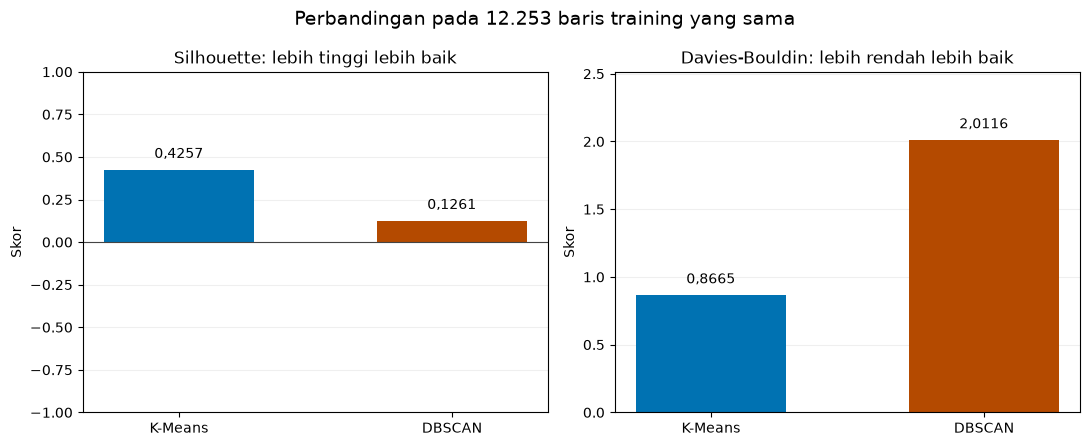

**Cara membaca:** kiri, cari batang yang lebih tinggi; kanan, cari batang yang lebih rendah. Sumbu kedua grafik berbeda karena makna skornya berbeda. Ini evaluasi pada subset identik, bukan seluruh baris K-Means dibandingkan dengan sebagian baris DBSCAN.

### Angka lengkap untuk dua cakupan evaluasi

,Model,Cakupan,Baris masukan,Baris masuk kelompok,Silhouette,DBI
0,K-Means,Seluruh training; skor DBSCAN hanya pada anggo...,13471,13471,0.3987,0.9328
1,DBSCAN,Seluruh training; skor DBSCAN hanya pada anggo...,13471,12253,0.1261,2.0116
2,K-Means,Subset identik; kedua model pada baris yang sama,12253,12253,0.4257,0.8665
3,DBSCAN,Subset identik; kedua model pada baris yang sama,12253,12253,0.1261,2.0116


Nilai Silhouette K-Means pada seluruh training dapat berbeda dari subset identik karena baris yang dinilai berbeda. Skor seleksi pada notebook 04/05 memakai rata-rata tiga sampel, sedangkan evaluasi ini memakai satu sampel tetap. Tidak ada model yang dilatih ulang di bagian ini.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, title in zip(axes, ["silhouette", "davies_bouldin"],
                            ["Silhouette: lebih tinggi lebih baik", "Davies-Bouldin: lebih rendah lebih baik"]):
    values = fair[metric].to_numpy()
    bars = ax.bar([model_names[key] for key in fair.index], values, color=[model_colors[key] for key in fair.index], width=.55)
    ax.bar_label(bars, labels=[angka(value) for value in values], padding=6)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel("Skor")
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    if metric == "silhouette":
        ax.set_ylim(-1, 1)
        ax.axhline(0, color="#444444", linewidth=.8)
    else:
        ax.set_ylim(0, max(values) * 1.25)
fig.suptitle(f"Perbandingan pada {jumlah(common.sum())} baris training yang sama", fontsize=14)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_scores_common_subset.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Cara membaca:** kiri, cari batang yang lebih tinggi; kanan, cari batang yang lebih rendah. Sumbu kedua grafik berbeda karena makna skornya berbeda. Ini evaluasi pada subset identik, bukan seluruh baris K-Means dibandingkan dengan sebagian baris DBSCAN."))
display(Markdown("### Angka lengkap untuk dua cakupan evaluasi"))
details = comparison[["model", "evaluation_scope", "n_rows", "n_assigned", "silhouette", "davies_bouldin"]].copy()
details["model"] = details["model"].map(model_names)
details["evaluation_scope"] = details["evaluation_scope"].map(lambda text: "Subset identik; kedua model pada baris yang sama" if text.startswith("subset identik") else "Seluruh training; skor DBSCAN hanya pada anggota kelompok")
display(details.rename(columns={"model": "Model", "evaluation_scope": "Cakupan", "n_rows": "Baris masukan", "n_assigned": "Baris masuk kelompok", "silhouette": "Silhouette", "davies_bouldin": "DBI"}).round(4))
display(Markdown("Nilai Silhouette K-Means pada seluruh training dapat berbeda dari subset identik karena baris yang dinilai berbeda. Skor seleksi pada notebook 04/05 memakai rata-rata tiga sampel, sedangkan evaluasi ini memakai satu sampel tetap. Tidak ada model yang dilatih ulang di bagian ini."))


<a id="s6"></a>
## 6. Grafik cakupan: masuk kelompok dan noise

Seluruh training layak menjadi penyebut di sini. Grafik menjawab berapa banyak data yang ditugaskan, bukan berapa banyak prediksi yang benar.

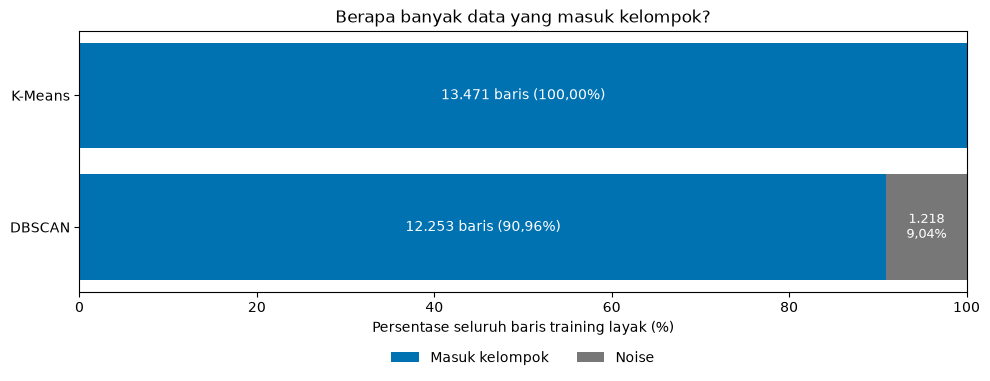

**Cara membaca:** panjang total setiap batang adalah 13.471 baris training layak.
K-Means selalu memberi kelompok; DBSCAN menempatkan 1.218 baris sebagai noise.
Karena itu 100% penugasan K-Means tidak berarti akurasi 100%, dan noise DBSCAN tidak otomatis berarti data salah.
Kotak tanpa kejadian tidak termasuk penyebut grafik ini karena tidak masuk training clustering.


In [6]:
assigned_counts = whole["n_assigned"].to_numpy(dtype=int)
noise_counts = whole["n_rows"].to_numpy(dtype=int) - assigned_counts
assigned_percent = assigned_counts / len(evaluation_train) * 100
noise_percent = noise_counts / len(evaluation_train) * 100
fig, ax = plt.subplots(figsize=(10, 4))
names = [model_names[key] for key in whole.index]
ax.barh(names, assigned_percent, color="#0072B2", label="Masuk kelompok")
ax.barh(names, noise_percent, left=assigned_percent, color="#777777", label="Noise")
for i, (assigned, noise) in enumerate(zip(assigned_counts, noise_counts)):
    ax.text(assigned_percent[i] / 2, i, f"{jumlah(assigned)} baris ({angka(assigned_percent[i], 2)}%)", ha="center", va="center", color="white")
    if noise:
        ax.text(assigned_percent[i] + noise_percent[i] / 2, i, jumlah(noise) + chr(10) + angka(noise_percent[i], 2) + "%", ha="center", va="center", color="white", fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Persentase seluruh baris training layak (%)", title="Berapa banyak data yang masuk kelompok?")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_assignment_coverage.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** panjang total setiap batang adalah {jumlah(len(evaluation_train))} baris training layak.
K-Means selalu memberi kelompok; DBSCAN menempatkan {jumlah(noise_counts[1])} baris sebagai noise.
Karena itu 100% penugasan K-Means tidak berarti akurasi 100%, dan noise DBSCAN tidak otomatis berarti data salah.
Kotak tanpa kejadian tidak termasuk penyebut grafik ini karena tidak masuk training clustering.
"""))


<a id="s7"></a>
## 7. Grafik jumlah anggota setiap kelompok

Bandingkan ukuran kelompok dan dukungan datanya. Huruf yang sama pada kedua metode tidak berarti kelompok yang sama.

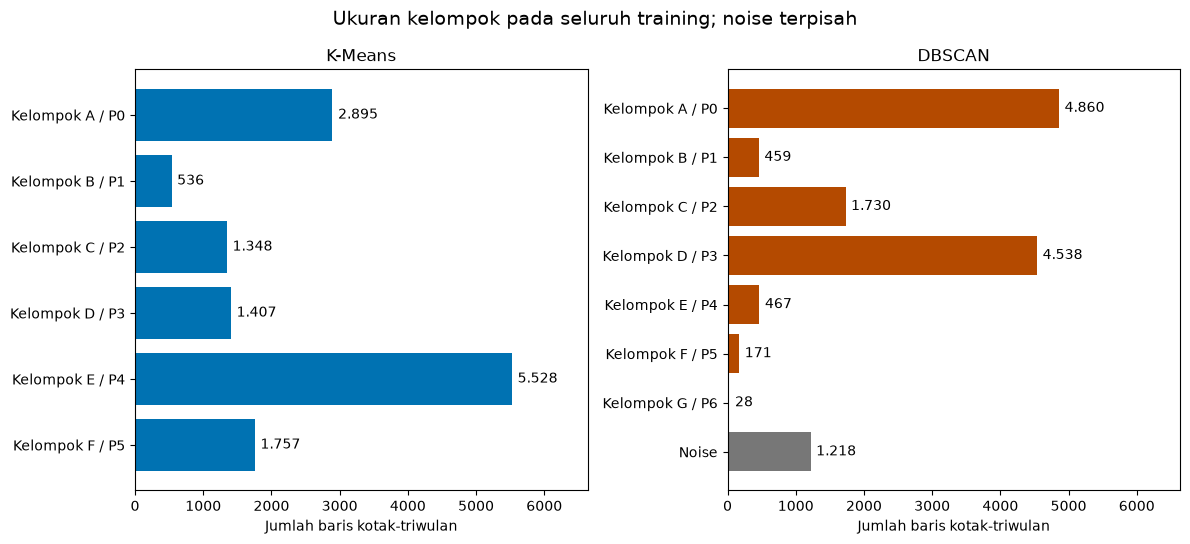

**Cara membaca:** lihat jumlah anggota masing-masing kelompok dan apakah ada kelompok sangat kecil atau dominan.
K-Means membentuk 6 kelompok; DBSCAN membentuk 7 kelompok di luar noise.
Kelompok terkecil DBSCAN memiliki 28 baris.
Huruf A pada K-Means tidak berarti kelompok yang sama dengan A pada DBSCAN.
Angka/huruf adalah pengenal, bukan peringkat bahaya. Jumlah kelompok lebih banyak juga tidak otomatis lebih baik.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True)
cluster_counts = {}
for ax, method in zip(axes, ["kmeans", "dbscan"]):
    unique, counts = np.unique(model_labels[method], return_counts=True)
    ordered = sorted(zip(unique, counts), key=lambda item: (item[0] < 0, item[0]))
    cluster_counts[method] = ordered
    names = ["Noise" if label < 0 else f"Kelompok {chr(65 + int(label))} / P{int(label)}" for label, _ in ordered]
    values = [count for _, count in ordered]
    bars = ax.barh(names, values, color=["#777777" if label < 0 else model_colors[method] for label, _ in ordered])
    ax.bar_label(bars, labels=[jumlah(value) for value in values], padding=4)
    ax.invert_yaxis()
    ax.set_title(model_names[method])
    ax.set_xlabel("Jumlah baris kotak-triwulan")
maximum_count = max(count for entries in cluster_counts.values() for _, count in entries)
axes[0].set_xlim(0, maximum_count * 1.2)
fig.suptitle("Ukuran kelompok pada seluruh training; noise terpisah", fontsize=14)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_cluster_sizes.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** lihat jumlah anggota masing-masing kelompok dan apakah ada kelompok sangat kecil atau dominan.
K-Means membentuk {int(whole.loc['kmeans', 'n_clusters'])} kelompok; DBSCAN membentuk {int(whole.loc['dbscan', 'n_clusters'])} kelompok di luar noise.
Kelompok terkecil DBSCAN memiliki {jumlah(whole.loc['dbscan', 'smallest_cluster_size'])} baris.
Huruf A pada K-Means tidak berarti kelompok yang sama dengan A pada DBSCAN.
Angka/huruf adalah pengenal, bukan peringkat bahaya. Jumlah kelompok lebih banyak juga tidak otomatis lebih baik.
"""))


<a id="s8"></a>
## 8. Grafik ciri kelompok dalam satuan asli

Grafik menampilkan rata-rata jumlah kejadian, magnitudo, dan kedalaman agar ciri kelompok mudah dibaca. Grafik pada kolom yang sama menggunakan skala sumbu yang sama.

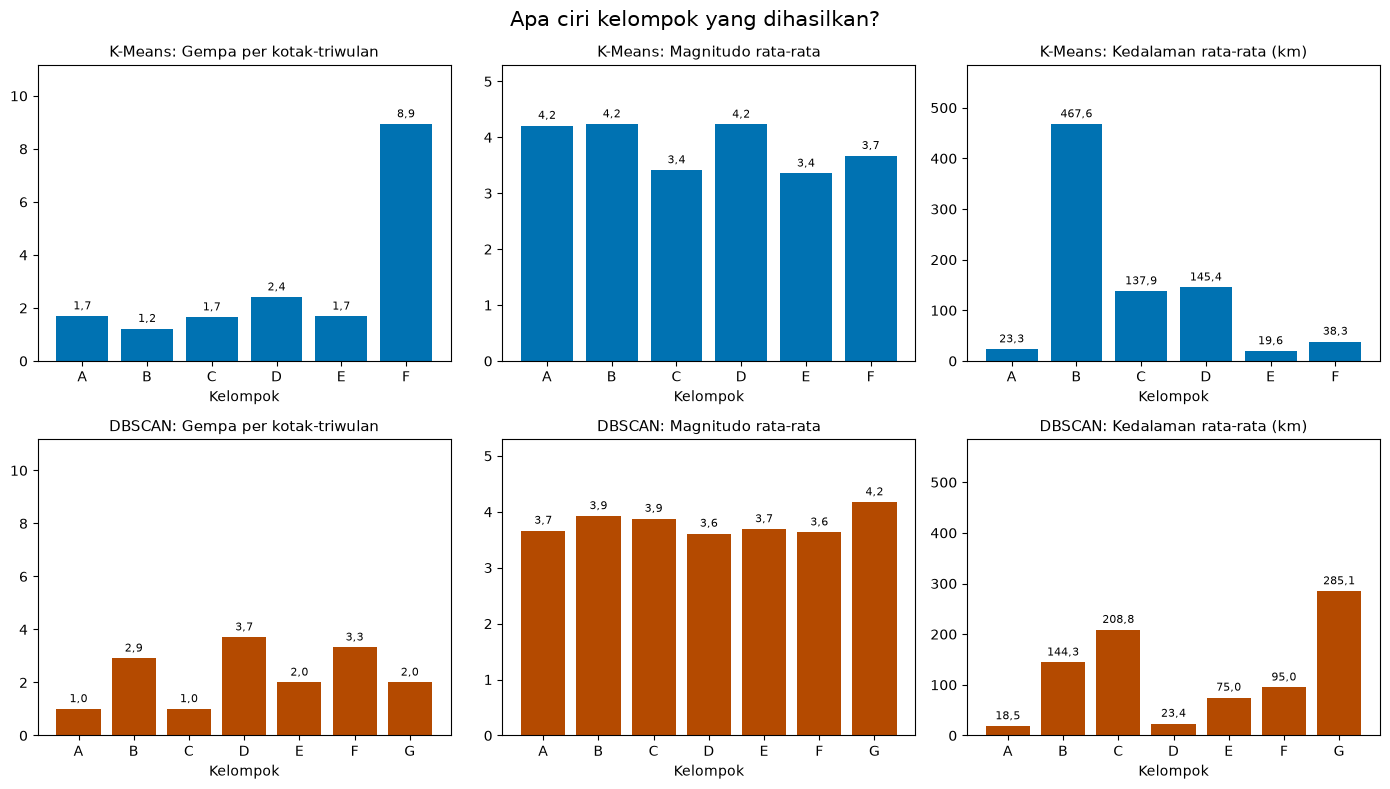

**Cara membaca:** bandingkan kolom yang sama karena satuannya sama. Kolom kiri menunjukkan rata-rata jumlah gempa, tengah magnitudo, kanan kedalaman. Angka merangkum rata-rata baris kotak-triwulan anggota kelompok, bukan setiap kejadian memiliki nilai yang sama. A–F K-Means dan A–G DBSCAN tidak berpasangan berdasarkan huruf. Grafik menampilkan tiga ciri dalam satuan asli; model tetap memakai lima fitur standar. Noise dikeluarkan dari grafik ciri kelompok ini; statistiknya tersedia pada tabel profil.

In [8]:
profile_frames = {method: pd.read_csv(ROOT / f"models/{method}/profiles.csv") for method in ["kmeans", "dbscan"]}
profile_columns = ["earthquake_count", "avg_magnitude", "avg_depth"]
profile_titles = ["Gempa per kotak-triwulan", "Magnitudo rata-rata", "Kedalaman rata-rata (km)"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, method in enumerate(["kmeans", "dbscan"]):
    frame = profile_frames[method].loc[lambda data: data["profile"].ne("NOISE")].copy()
    names = frame["profile"].map(lambda code: chr(65 + int(code.rsplit("P", 1)[1])))
    for col, (feature, title) in enumerate(zip(profile_columns, profile_titles)):
        ax = axes[row, col]
        bars = ax.bar(names, frame[feature], color=model_colors[method])
        ax.bar_label(bars, labels=[angka(value, 1) for value in frame[feature]], padding=3, fontsize=8)
        max_value = max(profile_frames[m].loc[lambda data: data["profile"].ne("NOISE"), feature].max() for m in profile_frames)
        ax.set_ylim(0, max_value * 1.25)
        ax.set_title(f"{model_names[method]}: {title}", fontsize=11)
        ax.set_xlabel("Kelompok")
fig.suptitle("Apa ciri kelompok yang dihasilkan?", fontsize=15)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_profile_characteristics.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Cara membaca:** bandingkan kolom yang sama karena satuannya sama. Kolom kiri menunjukkan rata-rata jumlah gempa, tengah magnitudo, kanan kedalaman. Angka merangkum rata-rata baris kotak-triwulan anggota kelompok, bukan setiap kejadian memiliki nilai yang sama. A–F K-Means dan A–G DBSCAN tidak berpasangan berdasarkan huruf. Grafik menampilkan tiga ciri dalam satuan asli; model tetap memakai lima fitur standar. Noise dikeluarkan dari grafik ciri kelompok ini; statistiknya tersedia pada tabel profil."))


<a id="s9"></a>
## 9. Grafik kesepakatan pengelompokan dan ARI

Periksa bagaimana baris yang sama dibagi oleh dua metode. Tidak ada label jawaban benar, sehingga grafik ini tidak digunakan untuk menghitung akurasi.

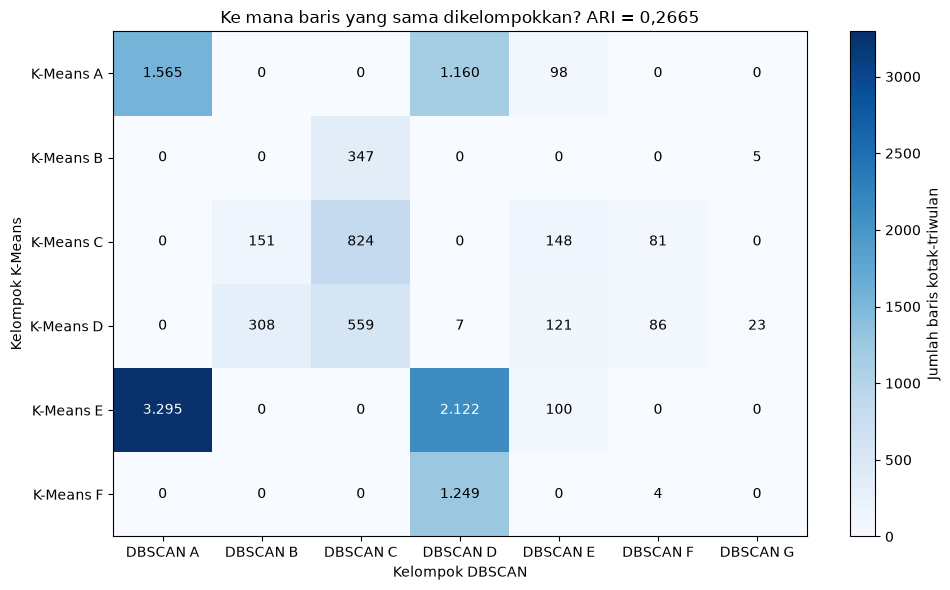

**Cara membaca:** pilih satu baris K-Means, lalu lihat ke kelompok DBSCAN mana anggotanya tersebar.
Sel lebih gelap berarti lebih banyak baris yang memiliki pasangan kelompok tersebut.
Grafik memakai 12.253 baris yang sama dan tidak memasukkan noise DBSCAN.

**Ini bukan confusion matrix akurasi:** tidak ada kelompok jawaban benar.
Diagonal tidak mempunyai arti benar/salah karena label dua metode tidak berpasangan berdasarkan huruf.
ARI sebesar **0,2665** merangkum kesepakatan pengelompokan:
1 berarti partisinya sama meskipun nama label berbeda; sekitar 0 setara kesepakatan acak menurut ukuran ini.
Hasil ini menunjukkan kedua metode tidak menghasilkan pembagian yang sama, bukan salah satunya memiliki akurasi 26,65%.


In [9]:
agreement_counts = pd.crosstab(pd.Series(km_model.labels_[common], name="K-Means"), pd.Series(db_model.labels_[common], name="DBSCAN"))
assert agreement_counts.to_numpy().sum() == common.sum()
ari = adjusted_rand_score(km_model.labels_[common], db_model.labels_[common])
fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(agreement_counts, cmap="Blues", aspect="auto", vmin=0)
for i in range(len(agreement_counts.index)):
    for j in range(len(agreement_counts.columns)):
        count = agreement_counts.iloc[i, j]
        ax.text(j, i, jumlah(count), ha="center", va="center", color="white" if count > agreement_counts.to_numpy().max() * .55 else "black")
ax.set_xticks(range(len(agreement_counts.columns)), [f"DBSCAN {chr(65 + int(label))}" for label in agreement_counts.columns])
ax.set_yticks(range(len(agreement_counts.index)), [f"K-Means {chr(65 + int(label))}" for label in agreement_counts.index])
ax.set(xlabel="Kelompok DBSCAN", ylabel="Kelompok K-Means", title=f"Ke mana baris yang sama dikelompokkan? ARI = {angka(ari)}")
fig.colorbar(image, ax=ax, label="Jumlah baris kotak-triwulan")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_partition_overlap.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** pilih satu baris K-Means, lalu lihat ke kelompok DBSCAN mana anggotanya tersebar.
Sel lebih gelap berarti lebih banyak baris yang memiliki pasangan kelompok tersebut.
Grafik memakai {jumlah(common.sum())} baris yang sama dan tidak memasukkan noise DBSCAN.

**Ini bukan confusion matrix akurasi:** tidak ada kelompok jawaban benar.
Diagonal tidak mempunyai arti benar/salah karena label dua metode tidak berpasangan berdasarkan huruf.
ARI sebesar **{angka(ari)}** merangkum kesepakatan pengelompokan:
1 berarti partisinya sama meskipun nama label berbeda; sekitar 0 setara kesepakatan acak menurut ukuran ini.
Hasil ini menunjukkan kedua metode tidak menghasilkan pembagian yang sama, bukan salah satunya memiliki akurasi {angka(ari * 100, 2)}%.
"""))


<a id="s10"></a>
## 10. Kesimpulan evaluasi, batas hasil, dan langkah berikutnya

Baca kesimpulan bersama cakupan data, ciri kelompok, dan uji sensitivitas. Satu skor tidak cukup untuk membuktikan kebenaran geologis suatu pengelompokan.

In [10]:
display(Markdown(f"""### Apa yang dapat disimpulkan?

| Pertanyaan | Hasil penelitian ini |
| --- | --- |
| Mana yang lebih terpisah menurut Silhouette dan DBI pada baris identik? | K-Means: Silhouette {angka(fair.loc['kmeans', 'silhouette'])}, DBI {angka(fair.loc['kmeans', 'davies_bouldin'])} |
| Apakah semua data harus masuk kelompok? | K-Means menugaskan seluruh baris; DBSCAN menyisakan {angka(whole.loc['dbscan', 'noise_fraction'] * 100, 2)}% noise |
| Apakah kedua metode membagi data dengan cara yang sama? | Tidak sama; kesepakatan ARI {angka(ari)} pada baris yang masuk kelompok DBSCAN |
| Apakah salah satu model sudah terbukti memprediksi gempa dengan benar? | Belum; penelitian ini tidak memiliki label kebenaran untuk menghitung akurasi |

**Penilaian yang dapat dipertanggungjawabkan:** K-Means memiliki pemisahan lebih baik pada dua metrik jarak yang digunakan.
DBSCAN tetap memberi sudut pandang tambahan melalui kelompok berbasis kepadatan dan noise,
tetapi pemisahannya masih lemah menurut Silhouette. Kedua metrik ini tidak menangkap seluruh sifat kelompok kepadatan DBSCAN.
Kita belum dapat menyatakan salah satu metode paling benar secara geologi hanya dari grafik ini.

Ukuran kelompok, ciri aktivitas, dan banyaknya kejadian yang mendasari tiap baris tetap perlu diperiksa.
Hasil juga dipengaruhi pemilihan fitur, batas magnitudo, ukuran grid, dan parameter.
Nama deskriptif dibuat setelah clustering; nama tersebut tidak mengubah anggota kelompok dan tidak menunjukkan tingkat risiko.

### Setelah evaluasi ini

- [Notebook 07](../07_temporal_analysis/07_temporal_analysis.ipynb): lihat perubahan kelompok setiap kotak sepanjang waktu.
- [Notebook 08](../08_stability/08_stability.ipynb): periksa kepekaan hasil terhadap parameter dan rancangan data.
- [Notebook 09](../09_testing_2026/09_testing_2026.ipynb): cocokkan aktivitas 2026 dengan kelompok historis.
- [Notebook 10](../10_gis_mapping/10_gis_mapping.ipynb): baca hasil pada peta.

### Tabel lengkap dan grafik untuk dibuka terpisah
"""))
display(FileLink(str(ROOT / "reports/evaluation/model_comparison.csv")))
display(FileLink(str(ROOT / "reports/evaluation/agreement.json")))
for filename in ["evaluation_scores_common_subset.png", "evaluation_assignment_coverage.png", "evaluation_cluster_sizes.png", "evaluation_profile_characteristics.png", "evaluation_partition_overlap.png"]:
    display(FileLink(str(ROOT / "reports/figures" / filename)))


### Apa yang dapat disimpulkan?

| Pertanyaan | Hasil penelitian ini |
| --- | --- |
| Mana yang lebih terpisah menurut Silhouette dan DBI pada baris identik? | K-Means: Silhouette 0,4257, DBI 0,8665 |
| Apakah semua data harus masuk kelompok? | K-Means menugaskan seluruh baris; DBSCAN menyisakan 9,04% noise |
| Apakah kedua metode membagi data dengan cara yang sama? | Tidak sama; kesepakatan ARI 0,2665 pada baris yang masuk kelompok DBSCAN |
| Apakah salah satu model sudah terbukti memprediksi gempa dengan benar? | Belum; penelitian ini tidak memiliki label kebenaran untuk menghitung akurasi |

**Penilaian yang dapat dipertanggungjawabkan:** K-Means memiliki pemisahan lebih baik pada dua metrik jarak yang digunakan.
DBSCAN tetap memberi sudut pandang tambahan melalui kelompok berbasis kepadatan dan noise,
tetapi pemisahannya masih lemah menurut Silhouette. Kedua metrik ini tidak menangkap seluruh sifat kelompok kepadatan DBSCAN.
Kita belum dapat menyatakan salah satu metode paling benar secara geologi hanya dari grafik ini.

Ukuran kelompok, ciri aktivitas, dan banyaknya kejadian yang mendasari tiap baris tetap perlu diperiksa.
Hasil juga dipengaruhi pemilihan fitur, batas magnitudo, ukuran grid, dan parameter.
Nama deskriptif dibuat setelah clustering; nama tersebut tidak mengubah anggota kelompok dan tidak menunjukkan tingkat risiko.

### Setelah evaluasi ini

- [Notebook 07](../07_temporal_analysis/07_temporal_analysis.ipynb): lihat perubahan kelompok setiap kotak sepanjang waktu.
- [Notebook 08](../08_stability/08_stability.ipynb): periksa kepekaan hasil terhadap parameter dan rancangan data.
- [Notebook 09](../09_testing_2026/09_testing_2026.ipynb): cocokkan aktivitas 2026 dengan kelompok historis.
- [Notebook 10](../10_gis_mapping/10_gis_mapping.ipynb): baca hasil pada peta.

### Tabel lengkap dan grafik untuk dibuka terpisah


C:\Users\yudhi\Documents\machine-learning\reports\evaluation\model_comparison.csv

C:\Users\yudhi\Documents\machine-learning\reports\evaluation\agreement.json

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_scores_common_subset.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_assignment_coverage.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_cluster_sizes.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_profile_characteristics.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_partition_overlap.png

## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.